In [ ]:
import re

import gensim.corpora as corpora
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from gensim.models import CoherenceModel
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.datasets import fetch_20newsgroups
from sklearn.decomposition import NMF, LatentDirichletAllocation, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

True

In [ ]:
# Load all categories
newsgroups = fetch_20newsgroups(
    subset="train",
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=42,
)

documents = newsgroups.data
labels = newsgroups.target
target_names = newsgroups.target_names

print(f"Total documents: {len(documents)}")
print(f"Number of categories: {len(target_names)}")
print(f"Categories: {target_names}")
print(f'\nFirst document preview:\n{"-"*60}')
print(documents[0][:500])

Total documents: 11314
Number of categories: 20
Categories: ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

First document preview:
------------------------------------------------------------
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car,

In [ ]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

# Add extra common words that are uninformative for topic modeling
extra_stopwords = {
    "would",
    "could",
    "also",
    "get",
    "like",
    "make",
    "may",
    "well",
    "even",
    "much",
    "many",
    "still",
    "say",
    "said",
}
stop_words.update(extra_stopwords)


# Lowercase -> Remove punctuation/digits -> Tokenize -> Remove stopwords -> Lemmatize
def preprocess_text(text):
    # Lowercase
    text = text.lower()
    # Remove punctuation and digits (keep letters and spaces)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    # Collapse multiple spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize_and_lemmatize(text):
    tokens = word_tokenize(text)
    # Remove stopwords and short tokens
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]
    # Lemmatize
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return tokens


# Batch preprocessing
print("Preprocessing documents...")
processed_texts = [preprocess_text(doc) for doc in documents]
tokenized_texts = [tokenize_and_lemmatize(text) for text in processed_texts]

# Keep a copy of the full processed text (joined by spaces) for vectorization
processed_docs = [" ".join(tokens) for tokens in tokenized_texts]

print("Preprocessing complete!")
print(f"\nFirst 200 characters of preprocessed document:\n{processed_docs[0][:200]}")
print(f"\nFirst 20 tokens:", tokenized_texts[0][:20])

Preprocessing documents...
Preprocessing complete!

First 200 characters of preprocessed document:
wondering anyone enlighten car saw day door sport car looked late early called bricklin door really small addition front bumper separate rest body know anyone tellme model name engine spec year produc

First 20 tokens: ['wondering', 'anyone', 'enlighten', 'car', 'saw', 'day', 'door', 'sport', 'car', 'looked', 'late', 'early', 'called', 'bricklin', 'door', 'really', 'small', 'addition', 'front', 'bumper']


In [ ]:
# Create dictionary
id2word = corpora.Dictionary(tokenized_texts)
# Filter extreme words (too rare or too frequent)
id2word.filter_extremes(no_below=5, no_above=0.5)

# Convert to BOW format
gensim_corpus = [id2word.doc2bow(tokens) for tokens in tokenized_texts]

print(f"Dictionary size: {len(id2word)} words")
print(f"Corpus documents: {len(gensim_corpus)}")

Dictionary size: 13867 words
Corpus documents: 11314


In [ ]:
# Tunable parameters
VEC_PARAMS = {
    "min_df": 5,  # Appear in at least 5 documents
    "max_df": 0.5,  # Appear in at most 50% of documents
    "ngram_range": (1, 1),  # Unigram only
    "max_features": 5000,  # Maximum number of features
    "stop_words": "english",  # sklearn built-in stopwords
}

# CountVectorizer (for LDA)
count_vectorizer = CountVectorizer(**VEC_PARAMS)
X_counts = count_vectorizer.fit_transform(processed_docs)
count_feature_names = count_vectorizer.get_feature_names_out()

print(f"CountVectorizer matrix shape: {X_counts.shape}")
print(f"Vocabulary size: {len(count_feature_names)}")

# TfidfVectorizer (for NMF and LSI)
tfidf_vectorizer = TfidfVectorizer(**VEC_PARAMS)
X_tfidf = tfidf_vectorizer.fit_transform(processed_docs)
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"TfidfVectorizer matrix shape: {X_tfidf.shape}")

CountVectorizer matrix shape: (11314, 5000)
Vocabulary size: 5000
TfidfVectorizer matrix shape: (11314, 5000)


In [ ]:
def get_topic_words(model, feature_names, n_top_words=10):
    topics = []
    components = model.components_

    for topic_idx in range(components.shape[0]):
        top_idx = components[topic_idx].argsort()[::-1][:n_top_words]
        top_words = [feature_names[i] for i in top_idx]
        topics.append(top_words)
    return topics


def calculate_coherence_sklearn(
    model, feature_names, tokenized_texts, id2word, n_top_words=20
):
    topics = get_topic_words(model, feature_names, n_top_words=n_top_words)

    coherence_model = CoherenceModel(
        topics=topics, texts=tokenized_texts, dictionary=id2word, coherence="c_v"
    )
    return coherence_model.get_coherence()

In [ ]:
K_MIN, K_MAX = 2, 25
k_range = range(K_MIN, K_MAX + 1)

# Store results
results = {
    "k": list(k_range),
    "lda_coherence": [],
    "lda_perplexity": [],
    "nmf_coherence": [],
    "lsi_coherence": [],
}

print(f"Starting model evaluation, k = {K_MIN} -> {K_MAX}")
print("=" * 60)

for k in k_range:
    print(f"\n>>> k = {k}")

    # LDA
    lda = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        max_iter=50,
        learning_method="batch",
        n_jobs=-1,
        verbose=0,
    )
    lda.fit(X_counts)

    perplexity = lda.perplexity(X_counts)
    coherence = calculate_coherence_sklearn(
        lda, count_feature_names, tokenized_texts, id2word
    )
    results["lda_coherence"].append(coherence)
    results["lda_perplexity"].append(perplexity)
    print(f"  LDA  | perplexity={perplexity:.1f} | coherence={coherence:.4f}")

    # NMF
    nmf = NMF(
        n_components=k,
        random_state=42,
        init="nndsvdar",
        solver="mu",
        max_iter=200,
        verbose=0,
    )
    nmf.fit(X_tfidf)
    coherence = calculate_coherence_sklearn(
        nmf, tfidf_feature_names, tokenized_texts, id2word
    )
    results["nmf_coherence"].append(coherence)
    print(f"  NMF  | coherence={coherence:.4f}")

    # LSI (TruncatedSVD)
    lsi = TruncatedSVD(n_components=k, random_state=42, n_iter=10)
    lsi.fit(X_tfidf)
    coherence = calculate_coherence_sklearn(
        lsi, tfidf_feature_names, tokenized_texts, id2word
    )
    results["lsi_coherence"].append(coherence)
    print(f"  LSI  | coherence={coherence:.4f}")

print("\n" + "=" * 60)
print("Evaluation complete!")

Starting model evaluation, k = 2 -> 25

>>> k = 2
  LDA  | perplexity=2186.5 | coherence=0.4614
  NMF  | coherence=0.5098
  LSI  | coherence=0.5241

>>> k = 3
  LDA  | perplexity=2059.0 | coherence=0.5015
  NMF  | coherence=0.6053
  LSI  | coherence=0.4118

>>> k = 4
  LDA  | perplexity=1949.6 | coherence=0.5371
  NMF  | coherence=0.6102
  LSI  | coherence=0.3962

>>> k = 5
  LDA  | perplexity=1890.2 | coherence=0.5456
  NMF  | coherence=0.6606
  LSI  | coherence=0.4816

>>> k = 6
  LDA  | perplexity=1824.8 | coherence=0.5440
  NMF  | coherence=0.6835
  LSI  | coherence=0.5023

>>> k = 7
  LDA  | perplexity=1759.4 | coherence=0.5885
  NMF  | coherence=0.6960
  LSI  | coherence=0.4982

>>> k = 8
  LDA  | perplexity=1733.1 | coherence=0.5687
  NMF  | coherence=0.7093
  LSI  | coherence=0.4641

>>> k = 9
  LDA  | perplexity=1708.6 | coherence=0.5837
  NMF  | coherence=0.7084
  LSI  | coherence=0.4801

>>> k = 10
  LDA  | perplexity=1659.6 | coherence=0.5775
  NMF  | coherence=0.6947
  LSI

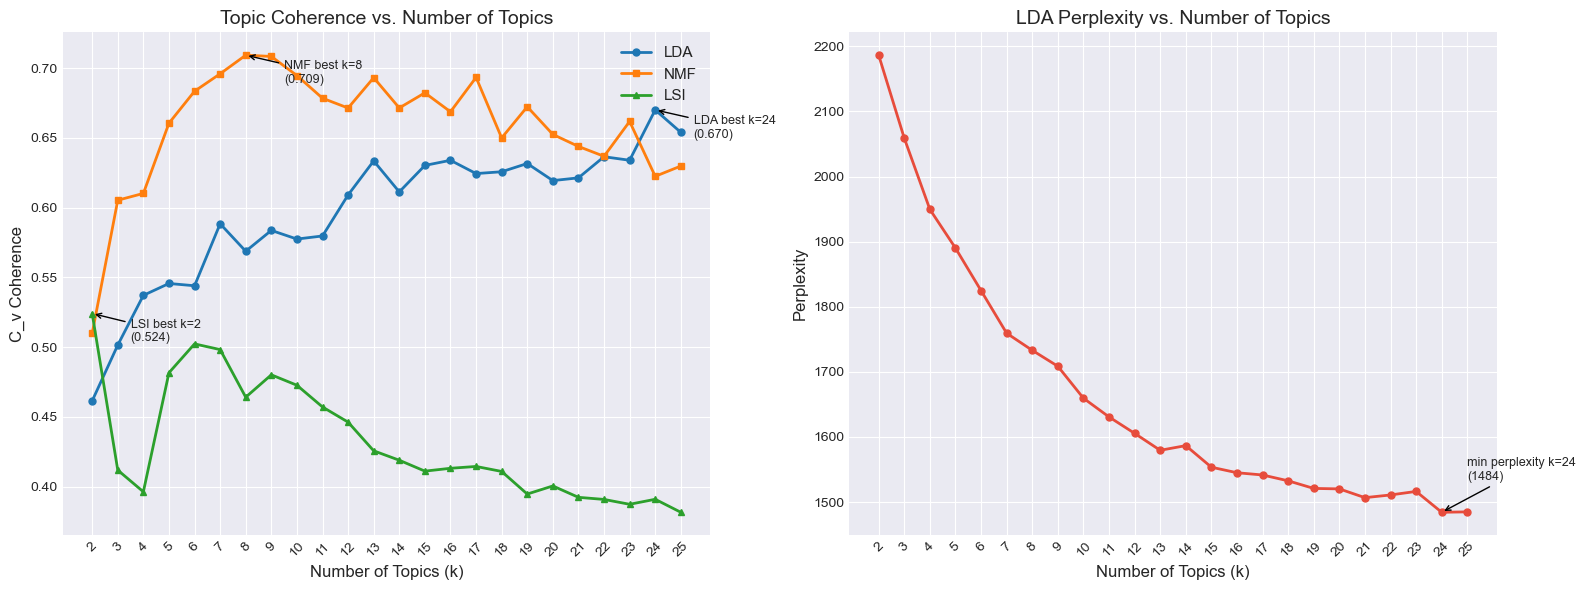

In [ ]:
plt.style.use("seaborn-v0_8-darkgrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Coherence
ax = axes[0]
ax.plot(
    results["k"], results["lda_coherence"], "o-", label="LDA", linewidth=2, markersize=5
)
ax.plot(
    results["k"], results["nmf_coherence"], "s-", label="NMF", linewidth=2, markersize=5
)
ax.plot(
    results["k"], results["lsi_coherence"], "^-", label="LSI", linewidth=2, markersize=5
)

# Annotate optimal values
for name, vals in [
    ("LDA", results["lda_coherence"]),
    ("NMF", results["nmf_coherence"]),
    ("LSI", results["lsi_coherence"]),
]:
    best_idx = np.argmax(vals)
    best_k = results["k"][best_idx]
    best_val = vals[best_idx]
    ax.annotate(
        f"{name} best k={best_k}\n({best_val:.3f})",
        xy=(best_k, best_val),
        xytext=(best_k + 1.5, best_val - 0.02),
        fontsize=9,
        arrowprops=dict(arrowstyle="->", lw=1),
    )

ax.set_xlabel("Number of Topics (k)", fontsize=12)
ax.set_ylabel("C_v Coherence", fontsize=12)
ax.set_title("Topic Coherence vs. Number of Topics", fontsize=14)
ax.legend(fontsize=11)
ax.set_xticks(results["k"])
ax.tick_params(axis="x", rotation=45)

# Right: Perplexity (LDA only)
ax = axes[1]
ax.plot(
    results["k"],
    results["lda_perplexity"],
    "o-",
    color="#e74c3c",
    linewidth=2,
    markersize=5,
)

# Annotate minimum perplexity
best_idx = np.argmin(results["lda_perplexity"])
best_k = results["k"][best_idx]
ax.annotate(
    f'min perplexity k={best_k}\n({results["lda_perplexity"][best_idx]:.0f})',
    xy=(best_k, results["lda_perplexity"][best_idx]),
    xytext=(best_k + 1, results["lda_perplexity"][best_idx] + 50),
    fontsize=9,
    arrowprops=dict(arrowstyle="->", lw=1),
)

ax.set_xlabel("Number of Topics (k)", fontsize=12)
ax.set_ylabel("Perplexity", fontsize=12)
ax.set_title("LDA Perplexity vs. Number of Topics", fontsize=14)
ax.set_xticks(results["k"])
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
df_results = pd.DataFrame(
    {
        "k": results["k"],
        "LDA Coherence": results["lda_coherence"],
        "NMF Coherence": results["nmf_coherence"],
        "LSI Coherence": results["lsi_coherence"],
        "LDA Perplexity": results["lda_perplexity"],
    }
)
print("Complete evaluation results:")
print(df_results.to_string(index=False))

# Best results summary
print("\n" + "=" * 60)
print("Best results summary:")
for name, col in [
    ("LDA", "LDA Coherence"),
    ("NMF", "NMF Coherence"),
    ("LSI", "LSI Coherence"),
]:
    best_idx = df_results[col].idxmax()
    row = df_results.iloc[best_idx]
    print(f'  {name}: k={int(row["k"])}, coherence={row[col]:.4f}')

Complete evaluation results:
 k  LDA Coherence  NMF Coherence  LSI Coherence  LDA Perplexity
 2       0.461413       0.509788       0.524086     2186.485399
 3       0.501452       0.605329       0.411754     2058.994370
 4       0.537094       0.610212       0.396220     1949.619470
 5       0.545615       0.660568       0.481595     1890.209320
 6       0.543989       0.683488       0.502294     1824.805023
 7       0.588451       0.696006       0.498203     1759.385581
 8       0.568735       0.709342       0.464059     1733.117343
 9       0.583684       0.708441       0.480108     1708.624903
10       0.577478       0.694727       0.472639     1659.552717
11       0.579692       0.678479       0.457048     1630.762421
12       0.609114       0.671450       0.446170     1605.543373
13       0.633519       0.693204       0.425613     1579.503614
14       0.611291       0.671507       0.418851     1586.688959
15       0.630283       0.682345       0.411037     1553.541015
16       0.

In [ ]:
best_k = {
    "LDA": results["k"][np.argmax(results["lda_coherence"])],
    "NMF": results["k"][np.argmax(results["nmf_coherence"])],
    "LSI": results["k"][np.argmax(results["lsi_coherence"])],
}
print("Optimal topic count per model:")
for name, k in best_k.items():
    print(f"  {name}: k = {k}")

# Retrain final models with optimal k
final_models = {}

# LDA
final_models["LDA"] = LatentDirichletAllocation(
    n_components=best_k["LDA"],
    random_state=42,
    max_iter=200,
    learning_method="batch",
    n_jobs=-1,
).fit(X_counts)

# NMF
final_models["NMF"] = NMF(
    n_components=best_k["NMF"],
    random_state=42,
    init="nndsvdar",
    solver="mu",
    max_iter=200,
).fit(X_tfidf)

# LSI
final_models["LSI"] = TruncatedSVD(n_components=best_k["LSI"], random_state=42).fit(
    X_tfidf
)

Optimal topic count per model:
  LDA: k = 24
  NMF: k = 8
  LSI: k = 2


In [ ]:
N_TOP_WORDS = 10

for model_name, model in final_models.items():
    print(f'\n{"=" * 60}')
    print(f"Model: {model_name}  (k = {best_k[model_name]})")
    print("=" * 60)

    # Select the corresponding feature names
    if model_name == "LDA":
        feature_names = count_feature_names
    else:
        feature_names = tfidf_feature_names

    topics = get_topic_words(model, feature_names, n_top_words=N_TOP_WORDS)

    for i, words in enumerate(topics):
        print(f'  Topic {i+1:2d}: {" | ".join(words)}')


Model: LDA  (k = 24)
  Topic  1: bank | pain | insurance | russian | edu | soon | good | pitt | gordon | day
  Topic  2: gun | weapon | state | firearm | right | crime | law | control | criminal | handgun
  Topic  3: drive | scsi | disk | hard | controller | bus | card | floppy | ide | port
  Topic  4: problem | time | case | use | cause | food | people | test | disease | drug
  Topic  5: cost | price | year | company | new | buy | water | money | market | order
  Topic  6: file | entry | output | program | line | section | rule | build | check | int
  Topic  7: government | law | right | court | new | fbi | privacy | case | policy | legal
  Topic  8: max | bhj | giz | chz | bxn | qax | rlk | air | okz | fyn
  Topic  9: mac | monitor | apple | offer | card | sale | mhz | new | video | chip
  Topic 10: hockey | play | team | game | period | goal | nhl | pt | new | shot
  Topic 11: space | nasa | launch | satellite | earth | mission | orbit | data | shuttle | moon
  Topic 12: thanks | w

In [ ]:
# Strategy: choose the model with the highest coherence
best_overall_model = None
best_overall_coherence = -1

print("Final model comparison:")
print(f'{"Model":<10} {"k":<5} {"Coherence":<15} {"Topics"}')
print("-" * 60)

for name in ["LDA", "NMF", "LSI"]:
    col = f"{name} Coherence"
    best_idx_local = df_results[col].idxmax()
    coh = df_results.loc[best_idx_local, col]
    k_val = int(df_results.loc[best_idx_local, "k"])
    marker = " <<<" if coh > best_overall_coherence else ""
    print(f"{name:<10} {k_val:<5} {coh:<15.4f} (k={k_val}){marker}")

    if coh > best_overall_coherence:
        best_overall_coherence = coh
        best_overall_model = name

print("-" * 60)
print(f"\nBest model: {best_overall_model} (coherence = {best_overall_coherence:.4f})")
print(f"Will use {best_overall_model} for prediction demo")

Final model comparison:
Model      k     Coherence       Topics
------------------------------------------------------------
LDA        24    0.6701          (k=24) <<<
NMF        8     0.7093          (k=8) <<<
LSI        2     0.5241          (k=2)
------------------------------------------------------------

Best model: NMF (coherence = 0.7093)
Will use NMF for prediction demo


In [ ]:
def predict_topics(
    text, model, vectorizer, feature_names, model_type="LDA", n_top_words=10, n_topics=5
):
    # Preprocess
    processed = preprocess_text(text)
    # Vectorize
    vec = vectorizer.transform([processed])

    # Get topic distribution
    if model_type == "LDA":
        # LDA: transform returns doc-topic distribution (Dirichlet posterior)
        topic_dist = model.transform(vec)[0]
    elif model_type == "NMF":
        # NMF: transform returns H matrix columns (topic weights), need normalization
        raw = model.transform(vec)[0]
        topic_dist = raw / (raw.sum() + 1e-10)
    else:  # LSI
        # LSI: SVD projection, take absolute value then normalize
        raw = np.abs(model.transform(vec)[0])
        topic_dist = raw / (raw.sum() + 1e-10)

    # Get top words for each topic
    topics = get_topic_words(model, feature_names, n_top_words=n_top_words)

    # Sort by descending probability
    sorted_idx = np.argsort(topic_dist)[::-1]

    print("=" * 60)
    if len(text) > 120:
        print(f"Input text preview: {text[:120]}...")
    else:
        print(f"Input text: {text}")
    print(f"Using model: {model_type}")
    print("=" * 60)

    for rank, idx in enumerate(sorted_idx[:n_topics]):
        prob = topic_dist[idx]
        words = topics[idx]
        print(f"\n  Topic #{idx+1} (rank {rank+1}) | Probability: {prob:.4f}")
        print(f'  Top {n_top_words} words: {" | ".join(words)}')

    print(f'\n{"-" * 60}')
    print(f"Full topic distribution ({len(topic_dist)} topics):")
    parts = [f"#{i+1}:{topic_dist[i]:.3f}" for i in sorted_idx]
    print("  | " + " | ".join(parts))

    return topic_dist

In [ ]:
# Use the best model, or manually specify one
demo_model_name = best_overall_model  # Auto-select the best model

demo_model = final_models[demo_model_name]
print(f"Demo using model: {demo_model_name}")

# Select the corresponding vectorizer and feature names
if demo_model_name == "LDA":
    demo_vectorizer = count_vectorizer
    demo_feature_names = count_feature_names
else:
    demo_vectorizer = tfidf_vectorizer
    demo_feature_names = tfidf_feature_names

Demo using model: NMF


In [ ]:
# ========== Test Texts ==========
test_texts = [
    """Graphics rendering is an important part of computer science.
    It involves rendering 3D models, textures, and lighting effects.
    Modern GPUs use sophisticated algorithms for image processing and
    real-time rendering in video games.""",
    """The patient was diagnosed with a rare disease affecting the immune
    system. Doctors prescribed a new treatment involving gene therapy and
    monoclonal antibodies. Clinical trials showed promising results for
    cancer patients.""",
    """The baseball game was exciting with the home team winning 5-3.
    The pitcher struck out 10 batters and the crowd was cheering
    throughout the game. The season is looking promising for the team.""",
    """The government announced new policies regarding international
    trade and diplomatic relations. The president addressed the nation
    about the importance of democratic values and human rights in
    foreign policy.""",
    """Machine learning and artificial intelligence are transforming
    industries. Deep neural networks can process large amounts of data
    and make accurate predictions. Natural language processing allows
    computers to understand human language.""",
]

print(f"Demonstrating {demo_model_name} on {len(test_texts)} new texts:")
for i, text in enumerate(test_texts):
    print(f'\n{"#" * 60}')
    print(f"Example {i+1}:")
    print(f'{"#" * 60}')
    predict_topics(
        text,
        demo_model,
        demo_vectorizer,
        demo_feature_names,
        model_type=demo_model_name,
        n_topics=3,
    )

Demonstrating NMF on 5 new texts:

############################################################
Example 1:
############################################################
Input text preview: Graphics rendering is an important part of computer science.
    It involves rendering 3D models, textures, and lighting...
Using model: NMF

  Topic #2 (rank 1) | Probability: 0.4858
  Top 10 words: window | file | driver | program | card | problem | use | version | color | using

  Topic #1 (rank 2) | Probability: 0.3169
  Top 10 words: people | think | time | right | thing | know | good | year | car | gun

  Topic #5 (rank 3) | Probability: 0.1048
  Top 10 words: key | chip | encryption | clipper | bit | phone | escrow | algorithm | government | use

------------------------------------------------------------
Full topic distribution (8 topics):
  | #2:0.486 | #1:0.317 | #5:0.105 | #4:0.092 | #7:0.001 | #8:0.000 | #3:0.000 | #6:0.000

############################################################
Exa